# Proyek Akhir: Menyelesaikan Permasalahan Perusahaan Edutech
## Jaya Jaya Institut · Early warning akhir semester satu

**Karya referensi independen untuk pembandingan; bukan karya pribadi peserta.**

- Nama: Reference project (AI-generated)
- Email: tidak berlaku untuk referensi
- Id Dicoding: tidak berlaku untuk referensi

Struktur mengikuti templat resmi Dicoding. Semua hasil numerik berikut dihitung dari CSV yang disertakan, bukan perkiraan naratif.

## Business Understanding
Jaya Jaya Institut adalah institusi fiktif yang ingin mendeteksi mahasiswa yang memerlukan pendampingan. Tujuan operasional: menghasilkan daftar untuk ditinjau pembimbing setelah semester satu. Target analitik: membedakan **Dropout** dan **Graduate** pada outcome yang sudah diketahui. **Enrolled** belum merupakan outcome selesai sehingga dikeluarkan hanya dari training/evaluation, tetap disertakan dalam dashboard.

Pertanyaan: (1) Seberapa besar dropout historis? (2) Bagaimana perbedaan indikator akademik dan finansial antarstatus? (3) Dapatkah indikator akhir semester satu memprioritaskan pendampingan?

Kriteria keberhasilan usulan: recall dropout validasi ≥80%, lalu pilih precision tertinggi untuk mengurangi beban tinjauan. Ini usulan desain, bukan target yang telah disetujui institusi. Tidak ada klaim pengurangan dropout tanpa eksperimen intervensi.

## Persiapan
### Menyiapkan library yang dibutuhkan
Jalankan dari folder proyek memakai Python 3.12 dan `requirements-dev.txt`. Seed 42 ditetapkan. Preprocessing dilatih dalam setiap fold untuk menghindari kebocoran.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/jaya-matplotlib')
import json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.common import ROOT, FEATURES, SEM, load_data, metrics, validate_inputs
plt.rcParams.update({'figure.figsize':(9,4.6),'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
COLORS={'Dropout':'#c45535','Enrolled':'#d9ae4b','Graduate':'#19756c'}

Matplotlib is building the font cache; this may take a moment.


### Menyiapkan data yang akan digunakan
Data dari [Dicoding](https://github.com/dicodingacademy/dicoding_dataset/blob/main/students_performance/README.md), bersumber dari [UCI, DOI 10.24432/C5MC89](https://doi.org/10.24432/C5MC89), berlisensi CC BY 4.0. Data berasal dari institusi pendidikan Portugal, bukan catatan nyata Jaya Jaya. Hasil tidak otomatis berlaku di Indonesia. File dibaca lokal agar tetap dapat direproduksi tanpa jaringan.

In [2]:
df=load_data()
print('SHA256:',hashlib.sha256((ROOT/'data/students_performance.csv').read_bytes()).hexdigest())
print('Dimensi:',df.shape)
display(df.head())

SHA256: a37dbda5555089a8d39b8be6f1a242f68403963a1f81423115c9676c8c7100e9
Dimensi: (4424, 37)


,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,...,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Data Understanding
Audit tipe, missing value, duplikasi, status, dan rentang indikator. Kode Course diperlakukan kategori; skala nilai masuk 0–200 dan semester 0–20. Nilai nol semester tidak diubah menjadi missing karena dapat mencerminkan tidak adanya kelulusan/evaluasi. Tidak ada ID mahasiswa atau tanggal kohort untuk memeriksa kebocoran antarindividu atau membuat temporal holdout.

In [3]:
audit=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()})
display(audit)
print('Duplikasi seluruh baris:',df.duplicated().sum())
display(df.describe().T)
validate_inputs(df)
assert set(df.Status)=={'Dropout','Enrolled','Graduate'}

,dtype,missing,unique
Marital_status,int64,0,6
Application_mode,int64,0,18
Application_order,int64,0,8
Course,int64,0,17
Daytime_evening_attendance,int64,0,2
Previous_qualification,int64,0,17
Previous_qualification_grade,float64,0,101
Nacionality,int64,0,21
Mothers_qualification,int64,0,29
Fathers_qualification,int64,0,34


Duplikasi seluruh baris: 0


,count,mean,std,min,25%,50%,75%,max
Marital_status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application_mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application_order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime_evening_attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous_qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mothers_qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Fathers_qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


### Distribusi outcome dan definisi penyebut
Dropout historis dashboard = jumlah Dropout / seluruh catatan, termasuk Enrolled. Prevalensi target model = Dropout / (Dropout + Graduate). Penyebut harus selalu ditulis agar kedua angka tidak tertukar.

,n,persen_seluruh
Status,,
Dropout,1421,32.120253
Enrolled,794,17.947559
Graduate,2209,49.932188


Dropout / seluruh catatan: 0.3212025316455696
Dropout / outcome selesai: 0.39146005509641874


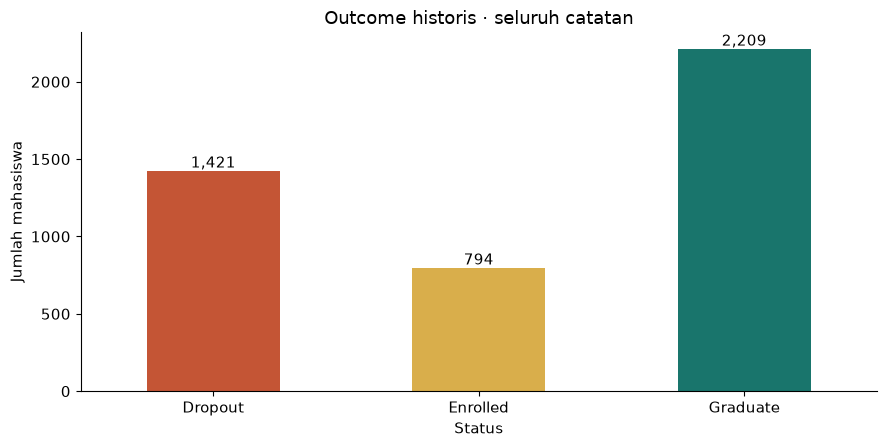

In [4]:
counts=df.Status.value_counts().reindex(['Dropout','Enrolled','Graduate'])
display(pd.DataFrame({'n':counts,'persen_seluruh':100*counts/len(df)}))
print('Dropout / seluruh catatan:',df.Status.eq('Dropout').mean())
resolved=df[df.Status.ne('Enrolled')].copy()
print('Dropout / outcome selesai:',resolved.Status.eq('Dropout').mean())
fig,ax=plt.subplots()
counts.plot.bar(ax=ax,color=[COLORS[s] for s in counts.index],rot=0)
ax.set(ylabel='Jumlah mahasiswa',title='Outcome historis · seluruh catatan',xlabel='Status')
for i,n in enumerate(counts): ax.text(i,n+25,f'{n:,}',ha='center')
fig.tight_layout(); fig.savefig(ROOT/'reports/status_distribution.png',dpi=160); plt.show()

### Indikator akademik dan finansial
Grafik akademik memperlihatkan distribusi, bukan hanya rata-rata. Grafik finansial memakai sumbu persentase 0–100 dan label ukuran kelompok. Hubungan observasional tidak membuktikan bahwa pembayaran atau beasiswa menyebabkan outcome; waktu pencatatan indikator finansial juga tidak tersedia. Karena itu indikator finansial tidak dipakai untuk model early warning.

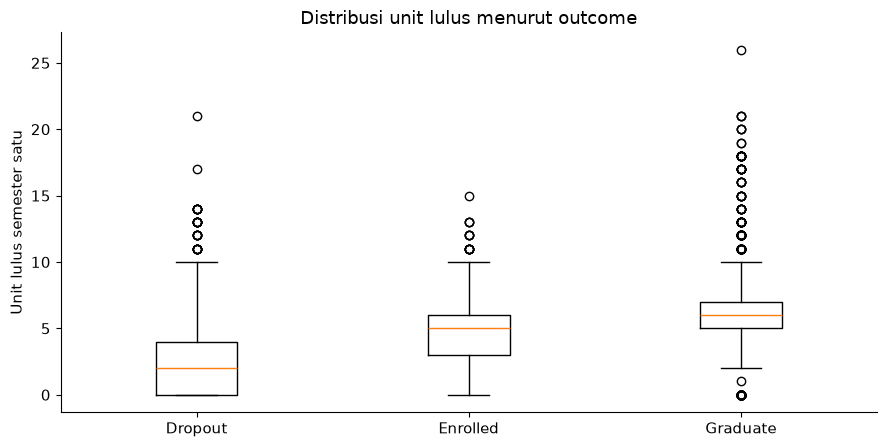

,n,dropout,persen
Tuition_fees_up_to_date,,,
0,528,457,86.553030
1,3896,964,24.743326


,n,dropout,persen
Scholarship_holder,,,
0,3325,1287,38.706767
1,1099,134,12.192903


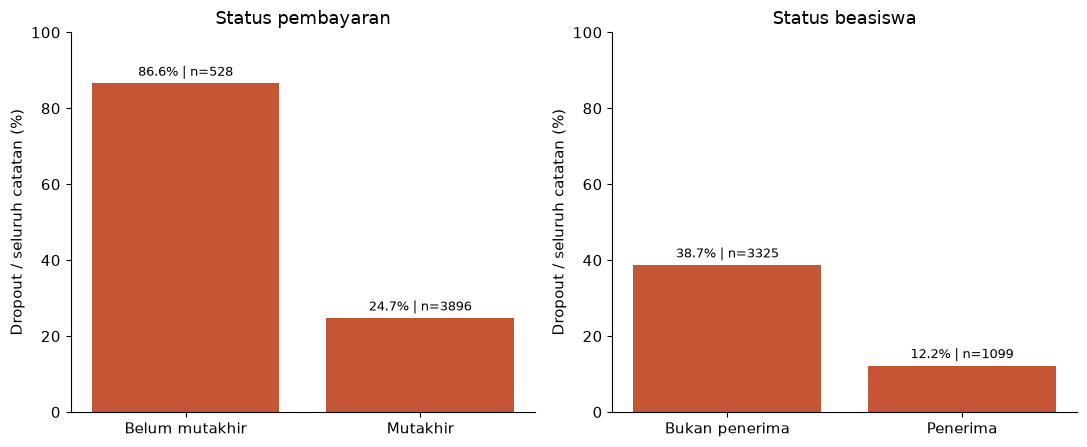

In [5]:
fig,ax=plt.subplots()
order=['Dropout','Enrolled','Graduate']
ax.boxplot([df.loc[df.Status.eq(s),SEM+'approved'] for s in order],tick_labels=order,showfliers=True)
ax.set(ylabel='Unit lulus semester satu',title='Distribusi unit lulus menurut outcome')
fig.tight_layout(); fig.savefig(ROOT/'reports/academic_distribution.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4.6))
for ax,col,title,labels in [(axes[0],'Tuition_fees_up_to_date','Status pembayaran',{0:'Belum mutakhir',1:'Mutakhir'}),(axes[1],'Scholarship_holder','Status beasiswa',{0:'Bukan penerima',1:'Penerima'})]:
    g=df.groupby(col).Status.agg(n='size',dropout=lambda s:s.eq('Dropout').sum())
    g['persen']=100*g.dropout/g.n
    ax.bar([labels[i] for i in g.index],g.persen,color='#c45535')
    ax.set(ylim=(0,100),ylabel='Dropout / seluruh catatan (%)',title=title)
    for i,row in enumerate(g.itertuples()): ax.text(i,row.persen+2,f'{row.persen:.1f}% | n={row.n}',ha='center',fontsize=9)
    display(g)
fig.tight_layout(); fig.savefig(ROOT/'reports/financial_associations.png',dpi=160); plt.show()

## Data Preparation / Preprocessing
Fitur model: 10 variabel akademik/administrasi (Course, waktu kuliah, nilai kualifikasi, nilai masuk, dan enam indikator semester satu). Tidak memakai semester dua, Status sebagai input, demografi, keuangan, atau ekonomi. Snapshot penggunaan paling awal adalah **setelah semester satu**; ini bukan model saat penerimaan. Waktu ekstraksi historis belum diverifikasi secara independen.

Pisahkan outcome selesai 60% train / 20% validation / 20% test dengan stratifikasi label dan seed 42. Median imputation (sebagai ketahanan pipeline), standard scaling numerik, dan one-hot kategori ditempatkan dalam pipeline. Tidak menggunakan SMOTE atau pemrosesan global sebelum split.

In [6]:
display(pd.DataFrame({'feature':FEATURES,'ketersediaan':['Penerimaan']*4+['Akhir semester satu']*6}))

,feature,ketersediaan
0,Course,Penerimaan
1,Daytime_evening_attendance,Penerimaan
2,Previous_qualification_grade,Penerimaan
3,Admission_grade,Penerimaan
4,Curricular_units_1st_sem_credited,Akhir semester satu
5,Curricular_units_1st_sem_enrolled,Akhir semester satu
6,Curricular_units_1st_sem_evaluations,Akhir semester satu
7,Curricular_units_1st_sem_approved,Akhir semester satu
8,Curricular_units_1st_sem_grade,Akhir semester satu
9,Curricular_units_1st_sem_without_evaluations,Akhir semester satu


## Modeling
Bandingkan prior baseline, logistic regression, random forest, dan histogram gradient boosting. Pilih model berdasarkan mean Average Precision (AP) dari 5-fold stratified cross-validation hanya pada train. AP merangkum ranking precision–recall; di sini disebut PR-AUC (AP), bukan luas trapezoid kurva PR. Training disediakan pada modul `src/train.py` yang juga menyimpan pipeline lengkap, split, prediksi test, dan jejak metrik. Sel berikut benar-benar menjalankan training ulang.

In [7]:
from src.train import train
report=train()
display(pd.DataFrame(report['cv_results'])[['model','cv_ap_mean','cv_ap_std']].sort_values('cv_ap_mean',ascending=False))
print('Model dipilih:',report['selected_model'])
display(pd.Series(report['split_counts'],name='n'))

{
  "provenance": {
    "source": "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/main/students_performance/data.csv",
    "sha256": "a37dbda5555089a8d39b8be6f1a242f68403963a1f81423115c9676c8c7100e9",
    "rows": 4424,
    "columns": 37,
    "missing_cells": 0,
    "duplicate_rows": 0,
    "status_counts": {
      "Graduate": 2209,
      "Dropout": 1421,
      "Enrolled": 794
    },
    "python": "3.12.7",
    "sklearn": "1.9.1"
  },
  "selected_model": "logistic",
  "feature_timing": "End of semester one; no semester-two, financial, macroeconomic or demographic fields used. Historical availability not independently time-stamped.",
  "features": [
    "Course",
    "Daytime_evening_attendance",
    "Previous_qualification_grade",
    "Admission_grade",
    "Curricular_units_1st_sem_credited",
    "Curricular_units_1st_sem_enrolled",
    "Curricular_units_1st_sem_evaluations",
    "Curricular_units_1st_sem_approved",
    "Curricular_units_1st_sem_grade",
    "Curricu

,model,cv_ap_mean,cv_ap_std
1,logistic,0.908894,0.007440
3,hist_gradient_boosting,0.900090,0.010088
2,random_forest,0.896825,0.010856
0,dummy_prior,0.391643,0.000685


Model dipilih: logistic


train         2178
validation     726
test           726
unresolved     794
Name: n, dtype: int64

## Evaluation
Ambang dipilih hanya pada validation: precision maksimum dengan recall ≥0,80. Setelah model dan ambang dibekukan, nilai pada test. Model tidak dilatih ulang pada test atau seluruh data; artefak deployment sama dengan artefak yang dievaluasi. Laporan memuat false positive (beban pembimbing) dan false negative (dropout terlewat), AP, ROC-AUC, F1/F2, balanced accuracy, dan Brier. Bootstrap 1.000 resample menghasilkan interval ketidakpastian test; interval ini bersyarat pada model tetap, bukan variasi semua kemungkinan training.

In [8]:
display(pd.DataFrame({'validation':report['validation'],'test':report['test'],'dummy_test':report['dummy_test']}).drop(index='confusion_matrix'))
print('Ambang:',report['threshold'])
display(pd.DataFrame(report['test']['confusion_matrix'],index=['Actual Graduate','Actual Dropout'],columns=['Pred Graduate','Pred Dropout']))
display(pd.DataFrame(report['test_ci95_bootstrap'],index=['2.5%','97.5%']).T)

,validation,test,dummy_test
pr_auc_ap,0.906598,0.920717,0.391185
roc_auc,0.916799,0.936229,0.5
precision,0.835165,0.812287,0.0
recall,0.802817,0.838028,0.0
f1,0.818671,0.824957,0.0
f2,0.809084,0.83275,0.0
balanced_accuracy,0.850503,0.856797,0.5
brier,0.102964,0.094441,0.238159
flagged,273,293,0
n,726,726,726


Ambang: 0.4557202141424468


,Pred Graduate,Pred Dropout
Actual Graduate,387,55
Actual Dropout,46,238


,2.5%,97.5%
pr_auc_ap,0.898628,0.944057
recall,0.796213,0.884204
precision,0.775423,0.856656


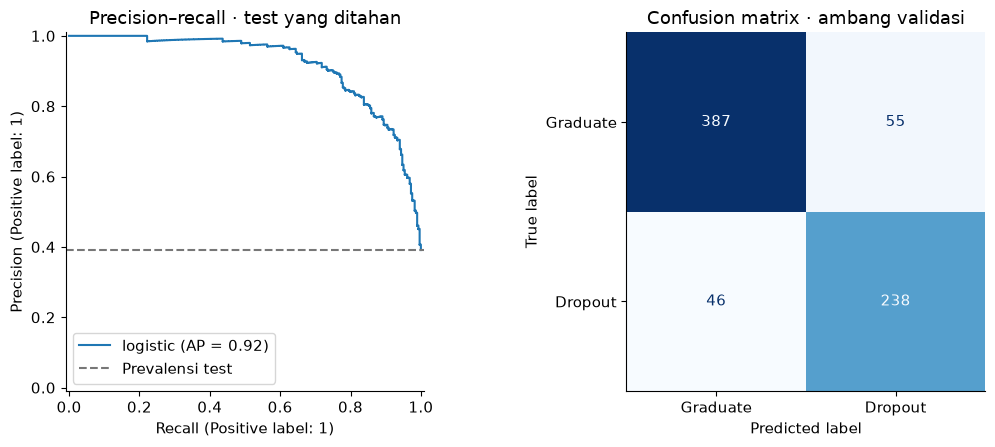

In [9]:
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
pred=pd.read_csv(ROOT/'reports/test_predictions.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4.6))
PrecisionRecallDisplay.from_predictions(pred.actual_dropout,pred.score,ax=axes[0],name=report['selected_model'])
axes[0].axhline(pred.actual_dropout.mean(),ls='--',color='#777777',label='Prevalensi test'); axes[0].legend()
axes[0].set(title='Precision–recall · test yang ditahan')
ConfusionMatrixDisplay(np.array(report['test']['confusion_matrix']),display_labels=['Graduate','Dropout']).plot(ax=axes[1],colorbar=False,cmap='Blues')
axes[1].set(title='Confusion matrix · ambang validasi')
fig.tight_layout(); fig.savefig(ROOT/'reports/model_evaluation.png',dpi=160); plt.show()

### Faktor prediktif dan keterbatasan
Permutation importance dihitung pada validation, menggunakan penurunan AP setelah satu fitur diacak. Fitur yang berkorelasi dapat saling menggantikan; importance bukan efek kausal atau alasan pasti untuk seorang mahasiswa. Generalisasi ke Enrolled memerlukan validasi prospektif karena label yang belum selesai dapat menciptakan selection bias. Tidak tersedia kohort/tanggal dan identitas untuk menguji temporal drift maupun overlap per mahasiswa.

,feature,ap_decrease_mean,ap_decrease_std
0,Curricular_units_1st_sem_approved,0.501981,0.013149
1,Curricular_units_1st_sem_enrolled,0.061378,0.008957
2,Curricular_units_1st_sem_credited,0.036517,0.007227
3,Course,0.035907,0.003904
4,Curricular_units_1st_sem_without_evaluations,0.015066,0.001120
5,Curricular_units_1st_sem_grade,0.012949,0.003390
6,Curricular_units_1st_sem_evaluations,0.009214,0.002976
7,Admission_grade,0.001595,0.000449
8,Daytime_evening_attendance,0.000432,0.000375
9,Previous_qualification_grade,0.000026,0.000039


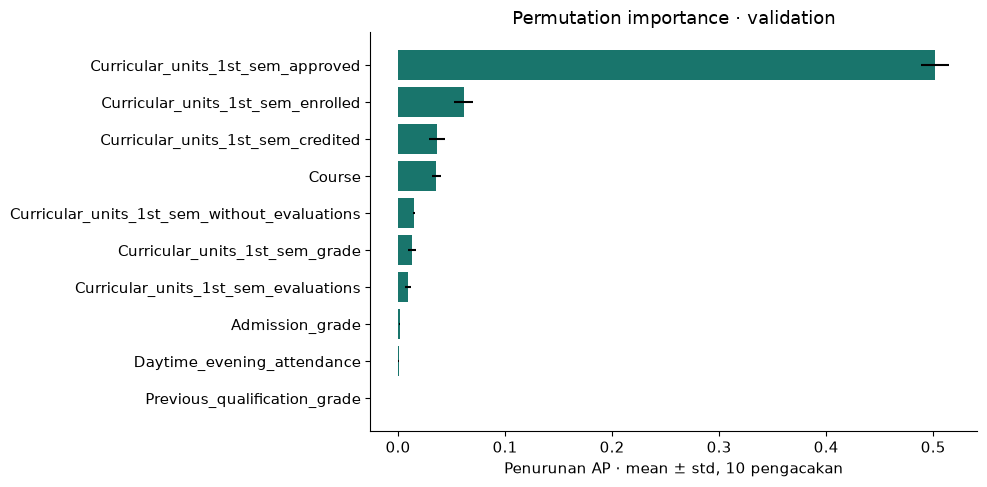

In [10]:
importance=pd.read_csv(ROOT/'reports/permutation_importance.csv')
display(importance)
fig,ax=plt.subplots(figsize=(10,5))
g=importance.sort_values('ap_decrease_mean')
ax.barh(g.feature,g.ap_decrease_mean,xerr=g.ap_decrease_std,color='#19756c')
ax.set(xlabel='Penurunan AP · mean ± std, 10 pengacakan',title='Permutation importance · validation')
fig.tight_layout(); fig.savefig(ROOT/'reports/feature_importance.png',dpi=160); plt.show()

## Deployment
Aplikasi `app.py` menyediakan prediksi individual, CSV, dashboard, serta batas penggunaan dan metrik. Jalankan `streamlit run app.py`. Metabase disediakan sebagai instance terpisah dengan ekspor database dan petunjuk pemulihan pada README. **Streamlit Community Cloud belum terverifikasi sampai URL aktual dan bukti akses tanpa login tersedia di `deployment.json`.** Petunjuk deployment saja tidak memenuhi kewajiban cloud. Lihat README untuk status aktual.

Simpan hanya artefak model yang dipercaya. File joblib adalah keluaran training proyek ini; jangan menggantinya dengan unggahan pengguna.

## Conclusion
Jawaban numerik berikut dihasilkan dari laporan evaluasi. Kemampuan model mengidentifikasi outcome historis tidak membuktikan bahwa intervensi akan mengurangi dropout.

In [11]:
m=report['test']; tn,fp= m['confusion_matrix'][0]; fn,tp=m['confusion_matrix'][1]
print(f"Dropout historis: {df.Status.eq('Dropout').sum():,}/{len(df):,} = {df.Status.eq('Dropout').mean():.2%}.")
print(f"Model {report['selected_model']}: AP test={m['pr_auc_ap']:.3f}, recall={m['recall']:.2%}, precision={m['precision']:.2%}.")
print(f"Pada {m['n']} baris test: {tp} dropout terdeteksi, {fn} terlewat, {fp} false positive, {tn} true negative.")
print('Ini bukti internal pada outcome selesai; belum validasi prospektif pada mahasiswa aktif.')

Dropout historis: 1,421/4,424 = 32.12%.
Model logistic: AP test=0.921, recall=83.80%, precision=81.23%.
Pada 726 baris test: 238 dropout terdeteksi, 46 terlewat, 55 false positive, 387 true negative.
Ini bukti internal pada outcome selesai; belum validasi prospektif pada mahasiswa aktif.


### Rekomendasi Action Items
1. **Kepala program & pembimbing:** pilot tinjauan sukarela setelah semester satu; verifikasi data dan hubungi kandidat dalam 7 hari kerja. Ukur proporsi berhasil dihubungi dan rencana pendampingan selesai; target waktu ini adalah usulan.
2. **Tim akademik:** tawarkan tutor/matrikulasi untuk mahasiswa dengan unit lulus rendah; evaluasi kehadiran dan unit lulus semester berikutnya.
3. **Layanan keuangan:** tawarkan konsultasi pembayaran/beasiswa berdasarkan kebutuhan yang dikonfirmasi. Asosiasi finansial pada dashboard bukan bukti sebab-akibat atau alasan sanksi.
4. **Tim data:** kumpulkan snapshot bertanggal dan label outcome kohort baru; audit recall/precision, kalibrasi, dan perbedaan antarkelompok, serta beban tinjauan bulanan.
5. **Pimpinan:** uji program pendampingan dengan desain terkontrol yang sesuai dan ukur retensi; jangan menyatakan penurunan dropout sebelum ada bukti hasil intervensi.